In [1]:
import os
import h5py
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
metadata_path = 'BraTS20 Training Metadata.csv'
data_dir = 'BraTS2020_training_data/content/data'

df = pd.read_csv(metadata_path)

df['slice_path'] = df['slice_path'].apply(
    lambda x: os.path.join(data_dir, os.path.basename(x))
)

all_volumes = df['volume'].unique()
np.random.seed(42)
np.random.shuffle(all_volumes)

train_vols = all_volumes[:70]
test_vols = all_volumes[70:100]

train_vols, val_vols = train_test_split(train_vols, test_size=0.2, random_state=42)

train_df = df[df['volume'].isin(train_vols)].reset_index(drop=True)
val_df = df[df['volume'].isin(val_vols)].reset_index(drop=True)

print(len(train_df), len(val_df))

8680 2170


In [3]:
with h5py.File(train_df.iloc[0]['slice_path'], 'r') as f:
    print(list(f.keys()))

['image', 'mask']


In [4]:
class BraTSDatasetSeg(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with h5py.File(row['slice_path'], 'r') as f:
            img = np.array(f['image'])
            mask = np.array(f['mask'])

        # -------- IMAGE FIX --------
        img = np.transpose(img, (2,0,1))[:3]
        img = img.astype(np.float32)
        for c in range(img.shape[0]):
            mask_c = img[c] > 0
            if mask_c.any():
                mean = img[c][mask_c].mean()
                std = img[c][mask_c].std()
                if std > 0:
                    img[c][mask_c] = (img[c][mask_c] - mean) / std

        # -------- MASK FIX (CRITICAL) --------
        if len(mask.shape) == 3:
            mask = np.max(mask, axis=2)   # take one channel

        mask = (mask > 0).astype(np.float32)

        img = torch.tensor(img, dtype=torch.float32)
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        # 🔥 RESIZE (BIG SPEED BOOST)
        img = torch.nn.functional.interpolate(img.unsqueeze(0), size=(128,128)).squeeze(0)
        mask = torch.nn.functional.interpolate(mask.unsqueeze(0), size=(128,128), mode='nearest').squeeze(0)   

        return img, mask

In [5]:
train_seg_dataset = BraTSDatasetSeg(train_df)
val_seg_dataset = BraTSDatasetSeg(val_df)

train_seg_loader = DataLoader(
    train_seg_dataset,
    batch_size=29,   # 🔥 increase batch
    shuffle=True,
    num_workers=2,
    pin_memory=True
)
val_seg_loader = DataLoader(val_seg_dataset, batch_size=8)

In [6]:
imgs, masks = next(iter(train_seg_loader))
print("IMG:", imgs.shape)
print("MASK:", masks.shape)

IMG: torch.Size([29, 3, 128, 128])
MASK: torch.Size([29, 1, 128, 128])


In [7]:
class DiceLoss(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)

        smooth = 1e-5
        intersection = (preds * targets).sum()
        union = preds.sum() + targets.sum()

        dice = (2. * intersection + smooth) / (union + smooth)
        return 1 - dice


class CombinedLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

    def forward(self, preds, targets):
        return self.bce(preds, targets) + self.dice(preds, targets)

In [8]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),

                nn.Conv2d(out_c, out_c, 3, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True)
            )

        self.enc1 = block(3,64)
        self.enc2 = block(64,128)
        self.enc3 = block(128,256)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = block(256,512)

        self.dropout = nn.Dropout(0.3)

        self.up3 = nn.ConvTranspose2d(512,256,2,2)
        self.dec3 = block(512,256)

        self.up2 = nn.ConvTranspose2d(256,128,2,2)
        self.dec2 = block(256,128)

        self.up1 = nn.ConvTranspose2d(128,64,2,2)
        self.dec1 = block(128,64)

        self.out = nn.Conv2d(64,1,1)

    def forward(self,x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.dropout(self.bottleneck(self.pool(e3)))

        d3 = self.up3(b)
        d3 = torch.cat([d3,e3],1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2,e2],1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1,e1],1)
        d1 = self.dec1(d1)

        return self.out(d1)

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

unet = UNet().to(device)

criterion = CombinedLoss()   # 🔥 NEW LOSS
optimizer = torch.optim.Adam(unet.parameters(), lr=1e-4)

scaler = torch.cuda.amp.GradScaler()

epochs = 15   # 👈 IMPORTANT (not 8)

for epoch in range(epochs):
    unet.train()
    train_loss = 0

    for imgs, masks in tqdm(train_seg_loader):

        imgs = imgs.to(device)
        masks = masks.to(device)

        if masks.dim() == 5:
            masks = masks.squeeze(4)

        with torch.cuda.amp.autocast():
            preds = unet(imgs)

            if preds.shape != masks.shape:
                masks = torch.nn.functional.interpolate(
                    masks, size=preds.shape[2:], mode='nearest'
                )

            loss = criterion(preds, masks)

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss += loss.item()

    print(f"Epoch {epoch+1} Loss: {train_loss:.4f}")

torch.save(unet.state_dict(), "unet_best.pth")
print("✅ HIGH-QUALITY U-Net Trained")

/tmp/ipykernel_9011/3853577594.py:8: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
  0%|          | 0/300 [00:00<?, ?it/s]/tmp/ipykernel_9011/3853577594.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
100%|██████████| 300/300 [04:13<00:00,  1.19it/s]


Epoch 1 Loss: 348.1745


100%|██████████| 300/300 [03:38<00:00,  1.37it/s]


Epoch 2 Loss: 285.9870


100%|██████████| 300/300 [05:03<00:00,  1.01s/it]


Epoch 3 Loss: 223.3017


... (20 outputs left out)

100%|██████████| 300/300 [05:40<00:00,  1.13s/it]


Epoch 14 Loss: 17.9969


100%|██████████| 300/300 [06:22<00:00,  1.28s/it]


Epoch 15 Loss: 17.3753
✅ HIGH-QUALITY U-Net Trained


In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

unet = UNet().to(device)
unet.load_state_dict(torch.load("unet_best.pth", map_location=device))  # use updated model
unet.eval()

UNet(
  (enc1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (enc2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (enc3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_r

In [11]:
def visualize_unet(volume_id, slice_index=50):

    vol_df = df[df['volume'] == volume_id].reset_index(drop=True)

    if len(vol_df) == 0:
        print("❌ Volume not found")
        return

    if slice_index >= len(vol_df):
        print("❌ Slice index out of range")
        return

    row = vol_df.iloc[slice_index]

    # LOAD FROM H5
    with h5py.File(row['slice_path'], 'r') as f:
        img = np.array(f['image'])
        mask = np.array(f['mask'])

    # -------- IMAGE FIX --------
    img = np.transpose(img, (2,0,1))[:3]
    img = img.astype(np.float32)
    for c in range(img.shape[0]):
        mask_c = img[c] > 0
        if mask_c.any():
            mean = img[c][mask_c].mean()
            std = img[c][mask_c].std()
            if std > 0:
                img[c][mask_c] = (img[c][mask_c] - mean) / std

    # -------- MASK FIX --------
    if len(mask.shape) == 3:
        mask = np.max(mask, axis=2)

    mask = (mask > 0).astype(np.float32)

    # -------- RESIZE (same as training) --------
    img_tensor = torch.tensor(img).unsqueeze(0)
    mask_tensor = torch.tensor(mask).unsqueeze(0).unsqueeze(0)

    img_tensor = torch.nn.functional.interpolate(img_tensor, size=(128,128))
    mask_tensor = torch.nn.functional.interpolate(mask_tensor, size=(128,128), mode='nearest')

    img_tensor = img_tensor.to(device)

    # -------- PREDICTION --------
    with torch.no_grad():
        pred = unet(img_tensor)
        pred = torch.sigmoid(pred)   # 🔥 IMPORTANT (since logits)

    pred = pred.squeeze().cpu().numpy()
    mask = mask_tensor.squeeze().cpu().numpy()

    # -------- VISUALIZATION --------
    img_np = img_tensor.squeeze().permute(1,2,0).cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() + 1e-8)

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.title("Image")
    plt.imshow(img_np)
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.title("True Mask")
    plt.imshow(mask, cmap='gray')
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.title("Predicted Mask")
    plt.imshow(pred > 0.5, cmap='gray')
    plt.axis('off')

    plt.show()

    # -------- TUMOR AREA --------
    tumor_pixels = np.sum(pred > 0.5)
    print(f"Tumor Pixel Count: {tumor_pixels}")
    print("Pred min:", pred.min(), "max:", pred.max())

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.7803295].


[ 41 185 135 306  40 140 359 310 249  95]


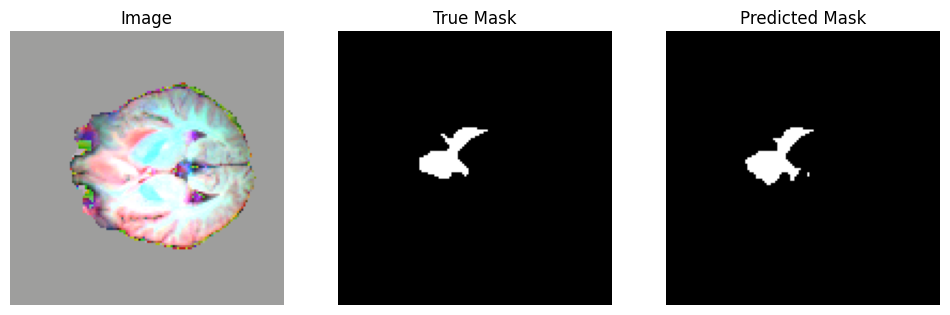

Tumor Pixel Count: 356
Pred min: 3.0998e-06 max: 1.0


In [15]:
print(df['volume'].unique()[:10])

test_volume = 152   # 👈 choose any

visualize_unet(test_volume, slice_index=66)

🧠 Initiating 3D Reconstruction for Volume 152...


/tmp/ipykernel_9011/1381128607.py:95: UserWarning: Glyph 128308 (\N{LARGE RED CIRCLE}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()


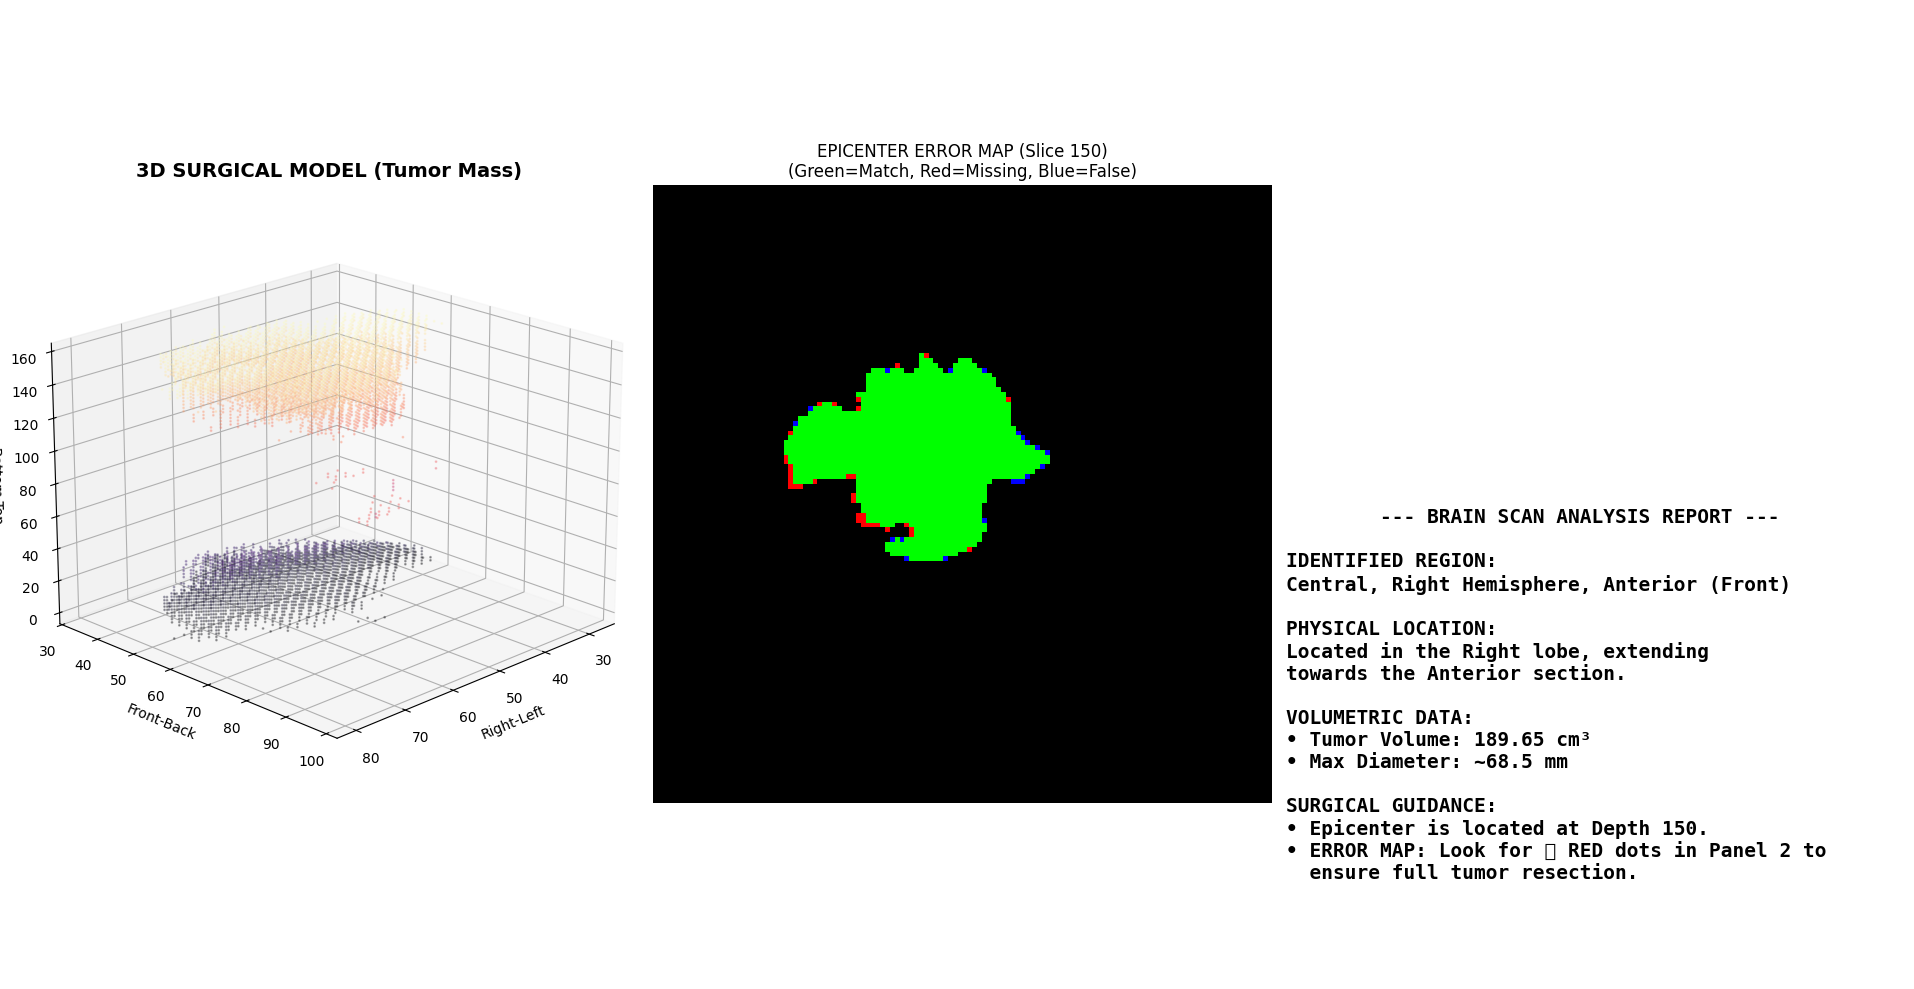

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

def advanced_neuro_surgical_analysis(volume_id):
    vol_df = df[df['volume'] == volume_id].sort_values('slice_path').reset_index(drop=True)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    all_preds = []
    all_masks = []
    
    print(f"🧠 Initiating 3D Reconstruction for Volume {volume_id}...")
    
    for idx in range(len(vol_df)):
        row = vol_df.iloc[idx]
        with h5py.File(row['slice_path'], 'r') as f:
            img = np.array(f['image'])
            mask = np.array(f['mask'])
            
        img = np.transpose(img, (2,0,1))[:3].astype(np.float32)
        for c in range(3):
            m_c = img[c] > 0
            if m_c.any(): img[c][m_c] = (img[c][m_c] - img[c][m_c].mean()) / (img[c][m_c].std() + 1e-8)
        
        img_t = torch.nn.functional.interpolate(torch.tensor(img).unsqueeze(0).to(device), size=(128,128))
        with torch.no_grad():
            pred = torch.sigmoid(unet(img_t)).squeeze().cpu().numpy()
        
        if len(mask.shape) == 3: mask = np.max(mask, axis=2)
        mask = cv2.resize((mask > 0).astype(np.float32), (128,128), interpolation=cv2.INTER_NEAREST)
        
        all_preds.append(pred > 0.5)
        all_masks.append(mask)

    all_preds = np.array(all_preds)
    all_masks = np.array(all_masks)

    # 1. ANATOMICAL LOCALIZATION LOGIC
    # Calculate Centroid of the Tumor Mass
    z_coords, y_coords, x_coords = np.where(all_preds)
    if len(z_coords) > 0:
        cz, cy, cx = np.mean(z_coords), np.mean(y_coords), np.mean(x_coords)
        
        # Determine Brain Region (Heuristic based on standard BraTS orientation)
        lat = "Left Hemisphere" if cx > 64 else "Right Hemisphere"
        vert = "Superior (Top)" if cz > 100 else "Inferior (Bottom)" if cz < 50 else "Central"
        depth = "Posterior (Back)" if cy > 64 else "Anterior (Front)"
        location_desc = f"{vert}, {lat}, {depth}"
    else:
        location_desc = "No Tumor Detected"

    # 2. VOLUMETRIC CALCULATIONS
    scale_factor = (240/128) ** 2
    tumor_volume_cm3 = (np.sum(all_preds) * scale_factor) / 1000
    epicenter_idx = np.argmax(np.sum(all_preds, axis=(1,2)))

    # 3. MULTI-PANEL 3D DASHBOARD
    fig = plt.figure(figsize=(20, 10))
    
    # --- PANEL 1: 3D TUMOR RECONSTRUCTION ---
    ax1 = fig.add_subplot(1, 3, 1, projection='3d')
    # Downsample for performance in plot
    ds = 2 
    z, y, x = np.where(all_preds[::ds, ::ds, ::ds])
    ax1.scatter(x*ds, y*ds, z*ds, c=z, cmap='magma', alpha=0.3, s=1)
    ax1.set_title("3D SURGICAL MODEL (Tumor Mass)", fontsize=14, fontweight='bold')
    ax1.set_xlabel("Right-Left"); ax1.set_ylabel("Front-Back"); ax1.set_zlabel("Bottom-Top")
    ax1.view_init(elev=20, azim=45)

    # --- PANEL 2: EPICENTER ERROR MAP ---
    ax2 = fig.add_subplot(1, 3, 2)
    tp = (all_preds[epicenter_idx] == 1) & (all_masks[epicenter_idx] == 1)
    fn = (all_preds[epicenter_idx] == 0) & (all_masks[epicenter_idx] == 1)
    fp = (all_preds[epicenter_idx] == 1) & (all_masks[epicenter_idx] == 0)
    error_map = np.zeros((128, 128, 3))
    error_map[tp] = [0, 1, 0]; error_map[fn] = [1, 0, 0]; error_map[fp] = [0, 0, 1]
    ax2.imshow(error_map)
    ax2.set_title(f"EPICENTER ERROR MAP (Slice {epicenter_idx})\n(Green=Match, Red=Missing, Blue=False)", fontsize=12)
    ax2.axis('off')

    # --- PANEL 3: CLINICAL LOCALIZATION REPORT ---
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.axis('off')
    report_text = (
        f"        --- BRAIN SCAN ANALYSIS REPORT ---\n\n"
        f"IDENTIFIED REGION:\n{location_desc}\n\n"
        f"PHYSICAL LOCATION:\nLocated in the {lat.split()[0]} lobe, extending\ntowards the {depth.split()[0]} section.\n\n"
        f"VOLUMETRIC DATA:\n"
        f"• Tumor Volume: {tumor_volume_cm3:.2f} cm³\n"
        f"• Max Diameter: ~{np.sqrt(np.sum(all_preds[epicenter_idx])*scale_factor):.1f} mm\n\n"
        f"SURGICAL GUIDANCE:\n"
        f"• Epicenter is located at Depth {epicenter_idx}.\n"
        f"• ERROR MAP: Look for 🔴 RED dots in Panel 2 to\n  ensure full tumor resection."
    )
    plt.text(0, 0.1, report_text, fontsize=14, fontweight='bold', family='monospace', verticalalignment='bottom')

    plt.tight_layout()
    plt.show()

# Run the Surgical Analysis
advanced_neuro_surgical_analysis(volume_id=152)
